# 00 — Data ingestion

Prepares the SST field every later notebook uses: the monthly surface
temperature (`ts`) of the CMIP6 MPI-ESM1.2-LR AMIP simulation.

1. Merge the two CMIP6 chunk files (1979–1998, 1999–2014) into one file.
2. Regrid to a regular 1° × 1° grid and mask land.
3. Quick check: map of the 1979–2013 climatology.

**Output:** `cfg.AMIP_TS_1DEG_MASKED_PATH` (read by `01` and `02`).

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import glob
import numpy as np
import xarray as xr
import xesmf as xe
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

## Step 1 — merge the raw CMIP6 files

In [2]:
def merge_files(folder, pattern, out_path):
    files = sorted(glob.glob(os.path.join(folder, pattern)))
    if not files:
        raise FileNotFoundError(f"no files matching {pattern} in {folder}")
    merged = xr.open_mfdataset(files, combine="by_coords")
    merged.to_netcdf(out_path)
    print(f"saved {out_path} ({len(files)} files)")


merge_files(cfg.CMIP6_AMIP_TS_DIR, "ts_Amon_MPI-ESM1-2-LR_amip_r1i1p1f1_gn_*.nc", cfg.AMIP_TS_RAW_PATH)

saved /work/mh1421/m301201/data/data-amip/ts_Amon_MPI-ESM1-2-LR_amip_r1i1p1f1_gn_197901-201412.nc (2 files)


## Step 2 — regrid to 1° and mask land

In [3]:
def regrid_to_grid(field, resolution=1.0):
    target = xr.Dataset({
        "lat": (["lat"], np.arange(-90, 90 + resolution / 2, resolution)),
        "lon": (["lon"], np.arange(0, 360, resolution)),
    })
    regridder = xe.Regridder(field, target, "bilinear", periodic=True)
    return regridder(field)


def load_ocean_mask(mask_path, like):
    mask = xr.open_dataset(mask_path)["slm"]          # 1 = land, 0 = ocean
    if "time" in mask.dims:
        mask = mask.isel(time=0)
    if "latitude" in mask.coords:
        mask = mask.rename({"latitude": "lat", "longitude": "lon"})
    return mask.interp(lat=like.lat, lon=like.lon, method="nearest")


sst = xr.open_dataset(cfg.AMIP_TS_RAW_PATH)["ts"]
sst_1deg = regrid_to_grid(sst, resolution=1.0)
sst_1deg.to_dataset(name="ts_regridded").to_netcdf(cfg.AMIP_TS_1DEG_PATH)
print("saved", cfg.AMIP_TS_1DEG_PATH)

mask = load_ocean_mask(cfg.MASK_PATH, sst_1deg.isel(time=0))
sst_masked = sst_1deg.where(mask == 0)
sst_masked.to_dataset(name="ts_regridded_masked").to_netcdf(cfg.AMIP_TS_1DEG_MASKED_PATH)
print("saved", cfg.AMIP_TS_1DEG_MASKED_PATH)

saved /work/mh1421/m301201/data/data-amip/ts_Amon_MPI-ESM1-2-LR_amip_r1i1p1f1_gn_197901-201412_1deg.nc
saved /work/mh1421/m301201/data/data-amip/ts_Amon_MPI-ESM1-2-LR_amip_r1i1p1f1_gn_197901-201412_1deg_masked.nc


## Step 3 — quick check: 1979–2013 SST climatology

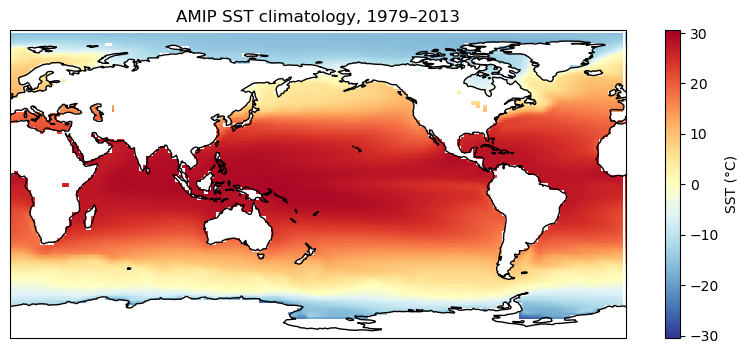

In [4]:
sst_c = xr.open_dataset(cfg.AMIP_TS_1DEG_MASKED_PATH)["ts_regridded_masked"] - 273.15
climatology = sst_c.sel(time=slice("1979-01", "2013-12")).mean("time")

plt.figure(figsize=(10, 4))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=180))
ax.coastlines()
climatology.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdYlBu_r", cbar_kwargs={"label": "SST (°C)"})
plt.title("AMIP SST climatology, 1979–2013")
plt.show()